# Fine-tuning QLoRA del redactor del agente (Ruta 1)

**Objetivo:** ajustar `Qwen2.5-3B-Instruct` (3 000 millones de parámetros) con QLoRA para que redacte respuestas con
el formato del agente: **Respuesta / Explicación / Fuentes**, citando los fragmentos recuperados y usando el
resultado de la herramienta sin recalcular. El fine-tuning aporta la **forma**; el **contenido** viene del RAG.

**Entorno:** Google Colab con GPU T4 gratuita (*Entorno de ejecución → Cambiar tipo de entorno → T4 GPU*) o Kaggle (GPU T4 x2).
Tiempo aproximado: 20–40 minutos en total.

**Salidas (evidencia del entrenamiento):**
- `evidencia/curva_perdida.png` y `evidencia/historial_entrenamiento.csv`
- `evidencia/configuracion.json` (hiperparámetros, versiones, GPU)
- `evidencia/muestras_validacion.md` (respuestas del modelo ajustado sobre el conjunto de validación)
- `lora_adapter/` (adaptador LoRA) y `arqui-qwen2.5-3b-ft.Q4_K_M.gguf` (modelo fusionado y cuantizado para CPU)

In [1]:
%%capture
!pip install unsloth

## 1. Datos
Se clona el repositorio para usar exactamente el dataset versionado (`data/finetune/`). Cambie la URL por la de su repositorio.

In [2]:
REPO = "https://github.com/Rafaelpaezz/agente-arquitectura.git"
!rm -rf agente-arquitectura && git clone -q $REPO
!wc -l agente-arquitectura/data/finetune/*.jsonl

   100 agente-arquitectura/data/finetune/train.jsonl
    10 agente-arquitectura/data/finetune/validacion.jsonl
   110 total


## 2. Modelo base cuantizado en 4 bits

In [3]:
import torch, json, platform
from unsloth import FastLanguageModel

MODELO_BASE = "unsloth/Qwen2.5-3B-Instruct-bnb-4bit"
MAX_SEQ = 4096

model, tokenizer = FastLanguageModel.from_pretrained(
    model_name=MODELO_BASE, max_seq_length=MAX_SEQ, load_in_4bit=True, dtype=None)
print(torch.cuda.get_device_name(0))

🦥 Unsloth: Will patch your computer to enable 2x faster free finetuning.


W1123 19:02:06.486000 639 torch/utils/_pytree.py:630] <enum 'KernelPreference'> is an Enum subclass and is now natively supported by torch.compile as an opaque value type. Calling register_constant() on Enum subclasses is deprecated and will be an error in a future release.
W1123 19:02:06.539000 639 torch/utils/_pytree.py:630] <enum 'ScaleCalculationMode'> is an Enum subclass and is now natively supported by torch.compile as an opaque value type. Calling register_constant() on Enum subclasses is deprecated and will be an error in a future release.


Unsloth: xformers is installed but cannot load with torch 2.14.1+cu130, so PyTorch attention is used instead.
To install a matching xformers, run `unsloth install-kernels xformers`, or `pip uninstall xformers` to hide this. UNSLOTH_ENABLE_LOGGING=1 shows the full error.
🦥 Unsloth Zoo will now patch everything to make training faster!
==((====))==  Unsloth 2026.11.10: Fast Qwen2 patching. Transformers: 5.17.0.
   \\   /|    Tesla T4. Num GPUs = 1. Max memory: 14.563 GB. Platform: Linux.
O^O/ \_/ \    Torch: 2.14.1+cu130. CUDA: 7.5. CUDA Toolkit: 13.0. Triton: 3.8.0
\        /    Bfloat16 = FALSE. FA [Xformers = None. FA2 = False]
 "-____-"     Free license: http://github.com/unslothai/unsloth
Unsloth: Fast downloading is enabled - ignore downloading bars which are red colored!


Loading weights:   0%|          | 0/434 [00:00<?, ?it/s]

Tesla T4


In [4]:
import torch
print("¿CUDA disponible en PyTorch?: ", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU detectada: ", torch.cuda.get_device_name(0))
else:
    print("No se detecta GPU. Por favor ve a 'Entorno de ejecución' -> 'Desconectarse y eliminar entorno de ejecución', y luego vuelve a iniciar el entorno con la GPU T4 seleccionada.")

¿CUDA disponible en PyTorch?:  True
GPU detectada:  Tesla T4


## 3. Adaptador LoRA
Solo se entrenan matrices de bajo rango (r = 16) sobre las proyecciones de atención y del MLP; los pesos base quedan congelados.

In [5]:
LORA = dict(r=16, lora_alpha=16, lora_dropout=0.0,
            target_modules=["q_proj", "k_proj", "v_proj", "o_proj", "gate_proj", "up_proj", "down_proj"])
model = FastLanguageModel.get_peft_model(model, **LORA, bias="none",
                                         use_gradient_checkpointing="unsloth", random_state=2026)
model.print_trainable_parameters()

Unsloth 2026.11.10 patched 36 layers with 36 QKV layers, 36 O layers and 36 MLP layers.


Unsloth: compiling each transformer block as one region (Qwen2DecoderLayer).
trainable params: 29,933,568 || all params: 3,115,872,256 || trainable%: 0.9607


## 4. Formato de chat
Cada ejemplo ya trae `messages` (sistema, usuario con fragmentos, asistente). Se aplica la plantilla ChatML de Qwen.

In [6]:
from datasets import load_dataset

ds = load_dataset("json", data_files={
    "train": "agente-arquitectura/data/finetune/train.jsonl",
    "validation": "agente-arquitectura/data/finetune/validacion.jsonl"})

def a_texto(lote):
    return {"text": [tokenizer.apply_chat_template(m, tokenize=False) for m in lote["messages"]]}

ds = ds.map(a_texto, batched=True)
largos = [len(tokenizer(t).input_ids) for t in ds["train"]["text"]]
print(ds, "\nTokens por ejemplo: máx", max(largos), "promedio", sum(largos) // len(largos))

Generating train split: 0 examples [00:00, ? examples/s]

Generating validation split: 0 examples [00:00, ? examples/s]

Map:   0%|          | 0/100 [00:00<?, ? examples/s]

Map:   0%|          | 0/10 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['id', 'tipo', 'messages', 'text'],
        num_rows: 100
    })
    validation: Dataset({
        features: ['id', 'tipo', 'messages', 'text'],
        num_rows: 10
    })
}) 
Tokens por ejemplo: máx 1635 promedio 1080


## 5. Entrenamiento
Se calcula la pérdida **solo sobre la respuesta del asistente** (`train_on_responses_only`): el modelo aprende a redactar, no a repetir los fragmentos.

In [7]:
from trl import SFTTrainer, SFTConfig
from unsloth.chat_templates import train_on_responses_only

HIPER = dict(per_device_train_batch_size=2, gradient_accumulation_steps=4, num_train_epochs=3,
             learning_rate=2e-4, warmup_steps=5, lr_scheduler_type="linear", weight_decay=0.01,
             optim="adamw_8bit", seed=2026)

trainer = SFTTrainer(
    model=model, tokenizer=tokenizer,
    train_dataset=ds["train"], eval_dataset=ds["validation"],
    args=SFTConfig(dataset_text_field="text", max_seq_length=MAX_SEQ, logging_steps=2,
                   eval_strategy="steps", eval_steps=6, output_dir="outputs", report_to="none", **HIPER))
trainer = train_on_responses_only(trainer, instruction_part="<|im_start|>user\n",
                                  response_part="<|im_start|>assistant\n")
stats = trainer.train()
print(stats)

Unsloth: Tokenizing ["text"] (num_proc=2):   0%|          | 0/100 [00:00<?, ? examples/s]

Unsloth: Packing train dataset (num_proc=2):   0%|          | 0/100 [00:00<?, ? examples/s]

Unsloth: Tokenizing ["text"] (num_proc=2):   0%|          | 0/10 [00:00<?, ? examples/s]

Unsloth: Packing is on by default - documents are packed into full rows with no cross-document attention. Set packing = False in SFTConfig (or UNSLOTH_DEFAULT_PACKING=0) to turn it off.


Map:   0%|          | 0/28 [00:00<?, ? examples/s]

Map:   0%|          | 0/10 [00:00<?, ? examples/s]

... (2 outputs left out)

Step,Training Loss,Validation Loss
6,0.845995,0.736728
12,0.689035,0.655236


Filter:   0%|          | 0/10 [00:00<?, ? examples/s]

Unsloth: Restored added_tokens_decoder metadata in outputs/checkpoint-12/tokenizer_config.json.


TrainOutput(global_step=12, training_loss=0.8199118673801422, metrics={'train_runtime': 394.0652, 'train_samples_per_second': 0.213, 'train_steps_per_second': 0.03, 'total_flos': 5453360740270080.0, 'train_loss': 0.8199118673801422, 'epoch': 3.0})


## 6. Evidencia del entrenamiento

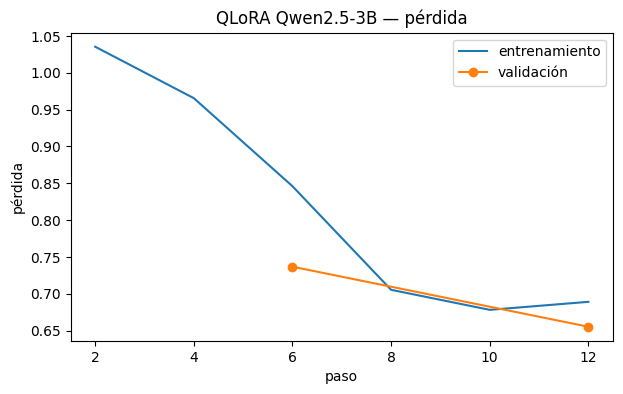

In [8]:
import os, pandas as pd, matplotlib.pyplot as plt
os.makedirs("evidencia", exist_ok=True)
hist = pd.DataFrame(trainer.state.log_history)
hist.to_csv("evidencia/historial_entrenamiento.csv", index=False)

fig, ax = plt.subplots(figsize=(7, 4))
t = hist.dropna(subset=["loss"]); v = hist.dropna(subset=["eval_loss"])
ax.plot(t["step"], t["loss"], label="entrenamiento")
ax.plot(v["step"], v["eval_loss"], marker="o", label="validación")
ax.set_xlabel("paso"); ax.set_ylabel("pérdida"); ax.set_title("QLoRA Qwen2.5-3B — pérdida"); ax.legend()
fig.savefig("evidencia/curva_perdida.png", dpi=150, bbox_inches="tight"); plt.show()

import transformers, trl, peft
json.dump({"modelo_base": MODELO_BASE, "max_seq_length": MAX_SEQ, "lora": LORA, "hiperparametros": HIPER,
           "ejemplos_train": len(ds["train"]), "ejemplos_validacion": len(ds["validation"]),
           "gpu": torch.cuda.get_device_name(0), "segundos_entrenamiento": stats.metrics["train_runtime"],
           "perdida_final": stats.metrics["train_loss"],
           "versiones": {"torch": torch.__version__, "transformers": transformers.__version__,
                         "trl": trl.__version__, "peft": peft.__version__}},
          open("evidencia/configuracion.json", "w"), indent=2, ensure_ascii=False)

## 7. Prueba rápida sobre el conjunto de validación

In [9]:
FastLanguageModel.for_inference(model)
salidas = []
for fila in ds["validation"]:
    prompt = tokenizer.apply_chat_template(fila["messages"][:-1], tokenize=False, add_generation_prompt=True)
    ids = tokenizer(prompt, return_tensors="pt").to("cuda")
    gen = model.generate(**ids, max_new_tokens=500, temperature=0.2, do_sample=True)
    texto = tokenizer.decode(gen[0][ids.input_ids.shape[1]:], skip_special_tokens=True)
    salidas.append(f"### {fila['id']}\n\n**Esperado:**\n\n{fila['messages'][-1]['content']}\n\n**Modelo ajustado:**\n\n{texto}\n")
open("evidencia/muestras_validacion.md", "w").write("\n".join(salidas))
print(salidas[0])

Both `max_new_tokens` (=500) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=500) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=500) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=500) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_gene

### CAL-013

**Esperado:**

**Respuesta:** La disponibilidad total es 98.9406 % (1.97 nueves), con una caída esperada de 3.87 días al año.
**Explicación:**
- Topología usada: serie(web=0.9995, api=0.99, bd=0.9999). En serie se multiplican las disponibilidades y en paralelo se calcula 1 − (1 − A1)(1 − A2)… [SDP, §Availability patterns > Availability in numbers > Availability in parallel vs in sequence]
- Caída esperada: 3.87 días al año y 7.74 h al mes (resultado de la herramienta).
- Eslabón más débil de la cadena principal: api=0.99. Puntos únicos de falla: web, api, bd.
- Mejora sugerida: duplicar en paralelo 'api' sube la disponibilidad a 99.9300 %, porque la redundancia en paralelo la aumenta. [SDP, §Availability patterns > Availability in numbers > Availability in parallel vs in sequence]
**Fuentes:** [SDP, §Availability patterns > Availability in numbers > Availability in parallel vs in sequence]

**Modelo ajustado:**

**Respuesta:** 98.9406%.
**Explicación:**
- Topología: serie 

## 8. Guardar adaptador y exportar a GGUF (CPU)
Se fusiona el adaptador con el modelo base y se cuantiza a `Q4_K_M` (~2 GB) para servirlo con Ollama en el VPS sin GPU.

In [10]:
model.save_pretrained("lora_adapter"); tokenizer.save_pretrained("lora_adapter")
model.save_pretrained_gguf("gguf", tokenizer, quantization_method="q4_k_m")
import glob, shutil
origen = glob.glob("gguf*/*Q4_K_M*.gguf") + glob.glob("*Q4_K_M*.gguf")
print(origen)
shutil.move(origen[0], "arqui-qwen2.5-3b-ft.Q4_K_M.gguf")
!ls -lh arqui-qwen2.5-3b-ft.Q4_K_M.gguf

Unsloth: Restored added_tokens_decoder metadata in lora_adapter/tokenizer_config.json.


Unsloth: Merging model weights to 16-bit format...


config.json:   0%|          | 0.00/757 [00:00<?, ?B/s]

model.safetensors.index.json:   0%|          | 0.00/35.6k [00:00<?, ?B/s]

Unsloth: Restored added_tokens_decoder metadata in gguf/tokenizer_config.json.


Found HuggingFace hub cache directory: /root/.cache/huggingface/hub


... (9 outputs left out)



Unsloth: Preparing safetensor model files: 100%|██████████| 2/2 [02:27<00:00, 73.57s/it]


Note: tokenizer.model not found (this is OK for non-SentencePiece models)


Unsloth: Merging weights into 16bit: 100%|██████████| 2/2 [02:17<00:00, 68.61s/it]


Unsloth: Merge process complete. Saved to `/content/gguf`
Unsloth: Converting to GGUF format...
==((====))==  Unsloth: Conversion from HF to GGUF information
   \\   /|    [0] Installing llama.cpp might take 3 minutes.
O^O/ \_/ \    [1] Converting HF to GGUF f16 might take 3 minutes.
\        /    [2] Converting GGUF f16 to ['q4_k_m'] might take 10 minutes each.
 "-____-"     In total, you will have to wait at least 16 minutes.

Unsloth: Installing llama.cpp. This might take 3 minutes...
Unsloth: Installing prebuilt llama.cpp b12649-mix-c7059d6 (app-b12649-mix-c7059d6-linux-x64-cpu.tar.gz) - skipping compilation.
Unsloth: Preparing converter script...
Unsloth: [1] Converting model into f16 GGUF format.
This might take 3 minutes...
Unsloth: Initial conversion completed! Files: ['gguf_gguf/Qwen2.5-3B-Instruct.F16.gguf']
Unsloth: [2] Converting GGUF f16 into q4_k_m. This might take 10 minutes...
Unsloth: Model files cleanup...
Unsloth: All GGUF conversions completed successfully!
Generate

## 9. Descargar
Guarde en Google Drive (más rápido para archivos grandes) o descargue directamente. Luego copie el `.gguf` al VPS en `deploy/ollama/`.

In [11]:
from google.colab import drive
drive.mount("/content/drive")
!mkdir -p /content/drive/MyDrive/agente-arquitectura
!cp -r evidencia lora_adapter arqui-qwen2.5-3b-ft.Q4_K_M.gguf /content/drive/MyDrive/agente-arquitectura/
print("Copiado a Drive: MyDrive/agente-arquitectura/")

Mounted at /content/drive
Copiado a Drive: MyDrive/agente-arquitectura/
